<center><h1>Patchou_Brice_HW6</h1></center>

Name: 
<br>
Github Username: 
<br>
USC ID: 

## 1. Tree-Based Methods

Import packages

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, roc_curve, auc, accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

### (a) Download the APS Failure data

In [29]:
# how do I fix this
# df = pd.read_csv('/Users/bricepatchou/Documents/GitHub/DCSI552_HW6/aps_failure_training_set.csv',skiprows=12, na_values=['?'])

file_path = '/Users/bricepatchou/Documents/GitHub/DCSI552_HW6/aps_failure_training_set.csv'
header_row = 0
with open(file_path, 'r') as f:
    for i, line in enumerate(f):
        if line.startswith('class'):
            header_row = i
            break

df = pd.read_csv(file_path, skiprows=header_row, na_values=['?'])

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

#### Listwise Deletion: Delete any row with at least one missing value
#### Simple Imputation: Replace missing data with Mean or Median
#### Arbitrary Value Replacement: Fill will random values

In [30]:


# features = df.drop(columns=['class'])
# labels = df['class']

# train_medians = features.median()


# features_imputed = features.fillna(train_medians)

# train_df_imputed = features_imputed.copy()
# train_df_imputed['class'] = labels

# how do i fix this

features = df.drop(columns=['class']).apply(pd.to_numeric, errors='coerce')
labels = df['class']

train_medians = features.median()
features_imputed = features.fillna(train_medians)

train_df_imputed = features_imputed.copy()
train_df_imputed['class'] = labels



#### (ii) Calculate the coefficient of variation

In [31]:
res = {}

for feat in features_imputed.columns:
    mean_val = features_imputed[feat].mean()
    std_val = features_imputed[feat].std() 
    
    # Prevent division by zero if mean is zero
    if mean_val != 0:
        
        cv = std_val / mean_val
        res[feat] = cv
    else:
        cv = float('nan')
        res[feat] = cv
        

    print(f'{feat} coefficient of variation: {cv}')

aa_000 coefficient of variation: 2.4509375779439706
ab_000 coefficient of variation: 10.38349386661712
ac_000 coefficient of variation: 2.3102406550036787
ad_000 coefficient of variation: 244.3228157593369
ae_000 coefficient of variation: 24.20013659749627
af_000 coefficient of variation: 19.47129505628922
ag_000 coefficient of variation: 92.91775503614396
ag_001 coefficient of variation: 35.249313535700715
ag_002 coefficient of variation: 17.565907132841453
ag_003 coefficient of variation: 8.64740247592642
ag_004 coefficient of variation: 5.463067171469747
ag_005 coefficient of variation: 2.956238698645589
ag_006 coefficient of variation: 2.356947701435076
ag_007 coefficient of variation: 2.858954303857639
ag_008 coefficient of variation: 6.221476788638559
ag_009 coefficient of variation: 33.3575674689091
ah_000 coefficient of variation: 2.3117348377320592
ai_000 coefficient of variation: 18.203806264001475
aj_000 coefficient of variation: 44.26599598906831
ak_000 coefficient of varia

#### (iii) Plot a correlation matrix

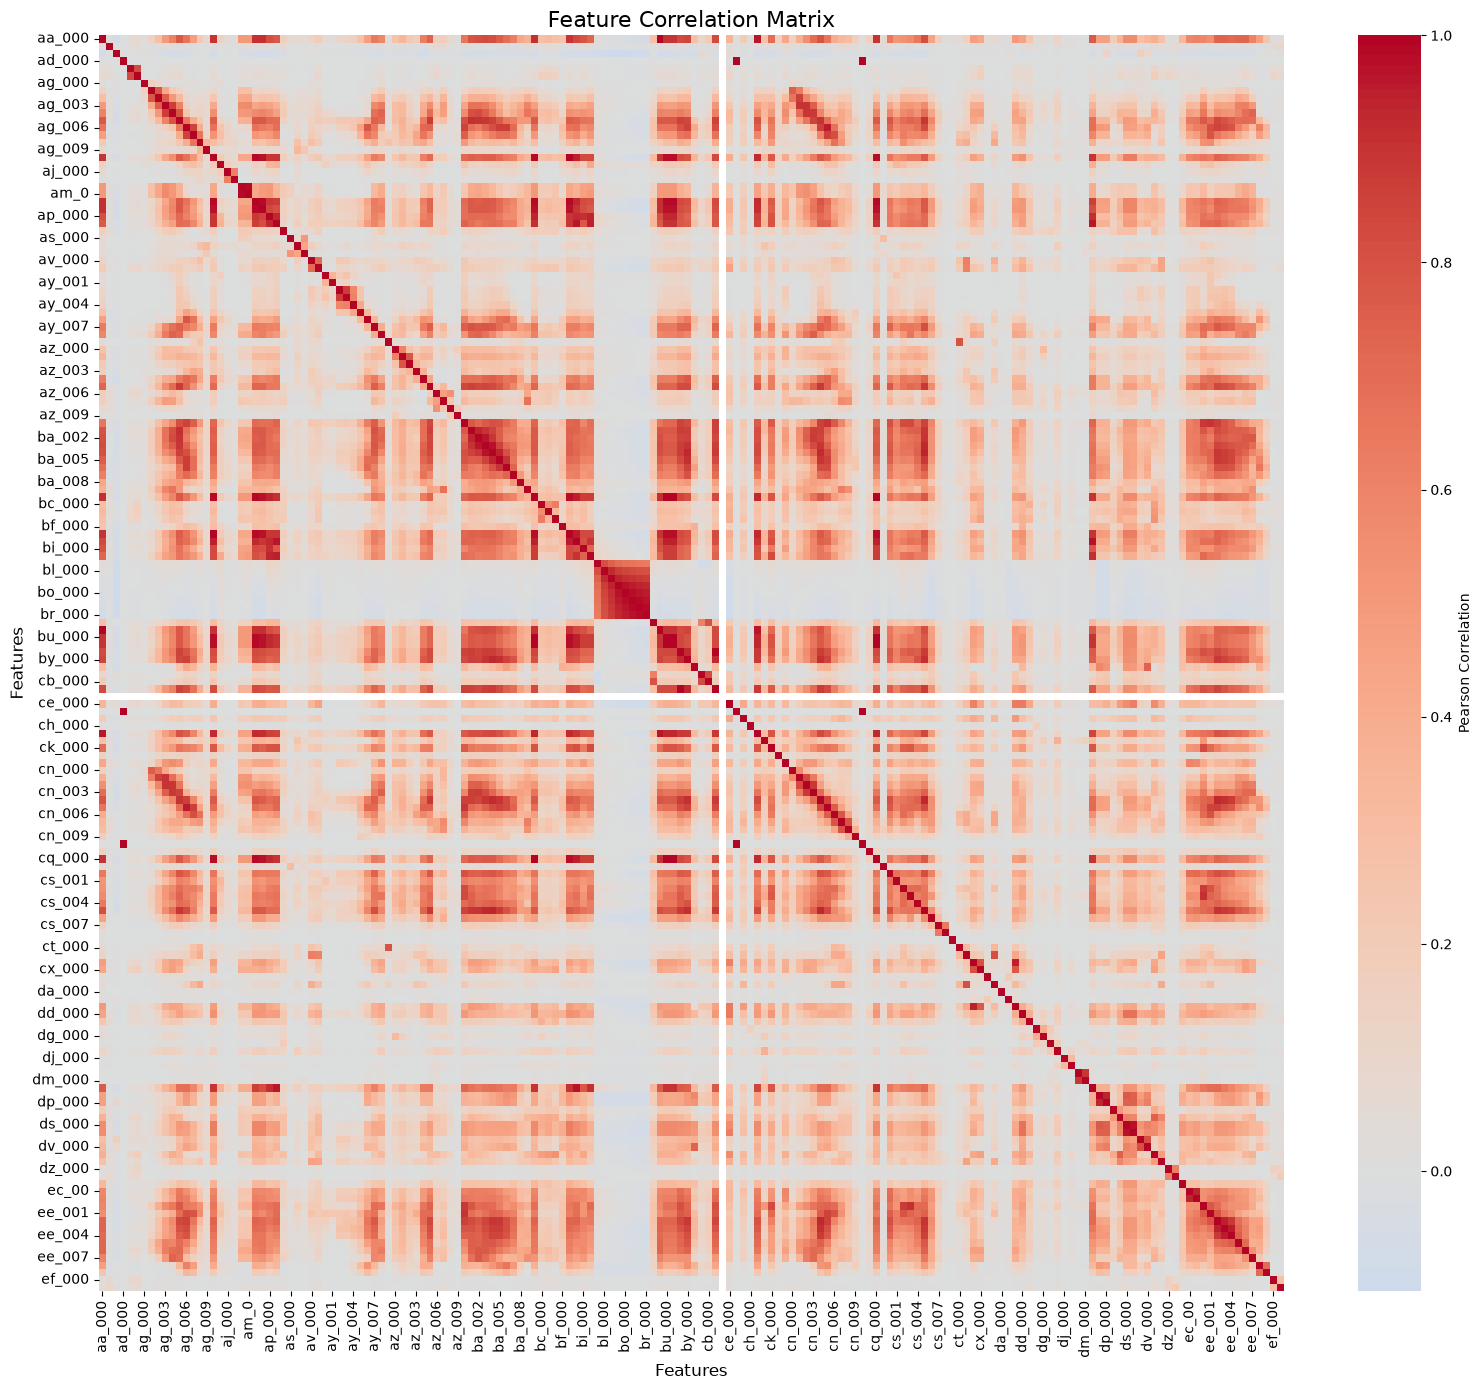

In [32]:

# how do i do this
corr_matrix = features_imputed.corr()


plt.figure(figsize=(16, 14))

sns.heatmap(corr_matrix, cmap='coolwarm',center=0,annot=False,cbar_kws={'label': 'Pearson Correlation'})

plt.title('Feature Correlation Matrix', fontsize=16)
plt.xlabel('Features', fontsize=12)
plt.ylabel('Features', fontsize=12)

plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

####

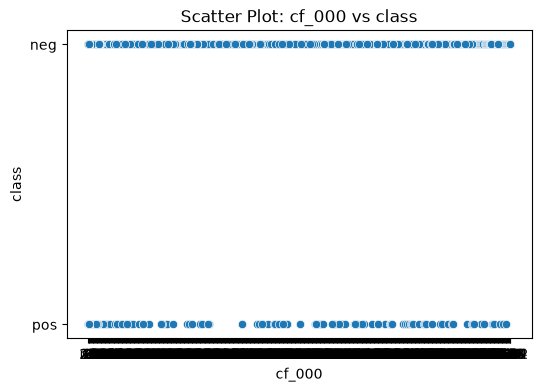

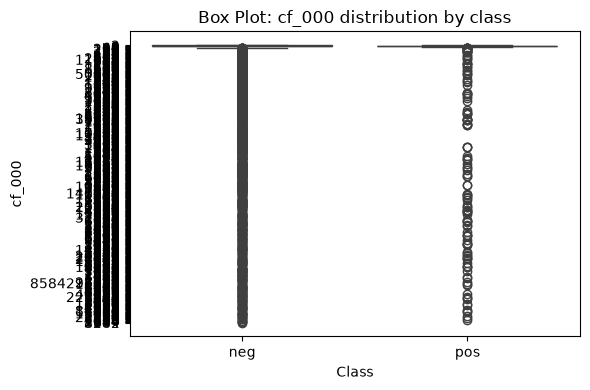

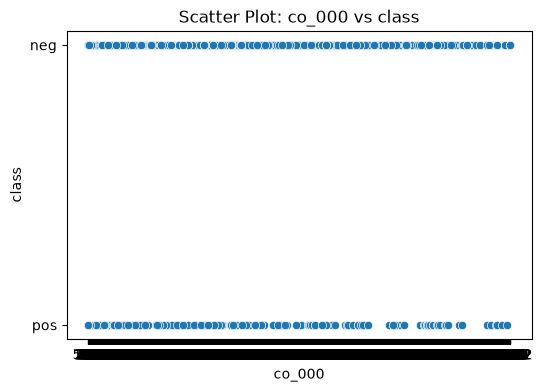

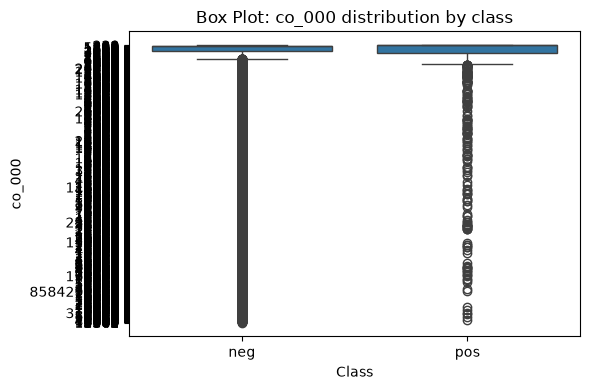

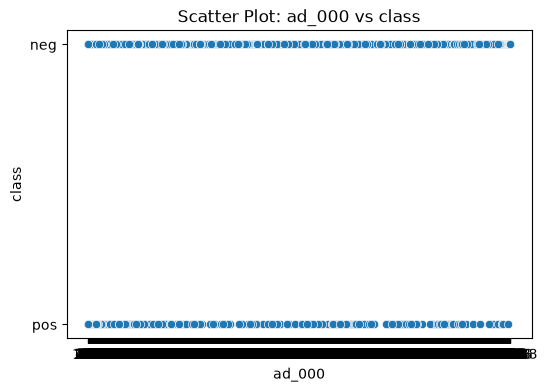

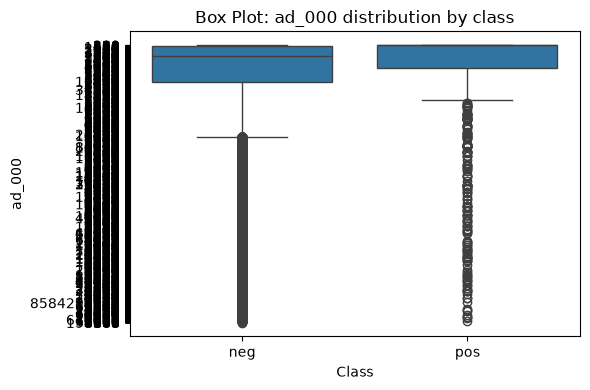

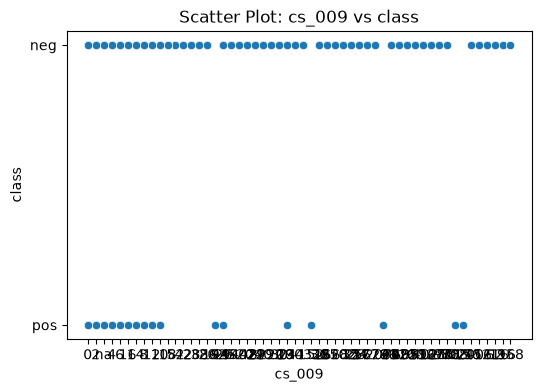

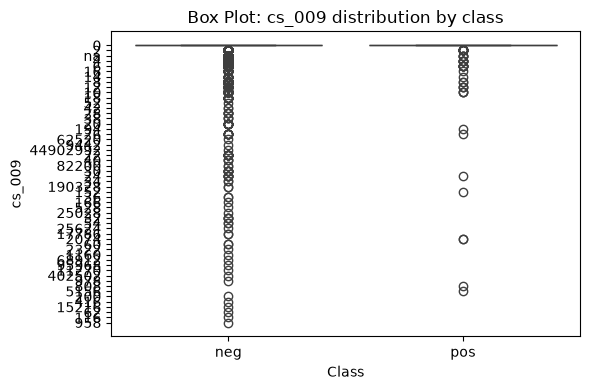

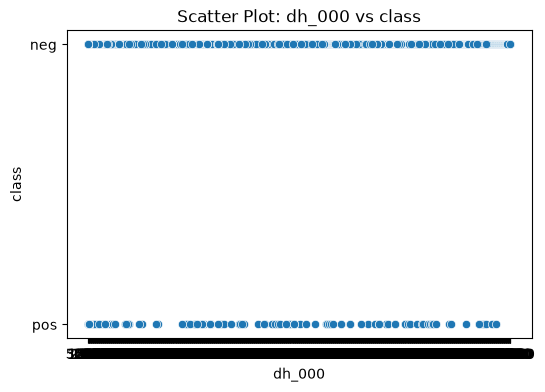

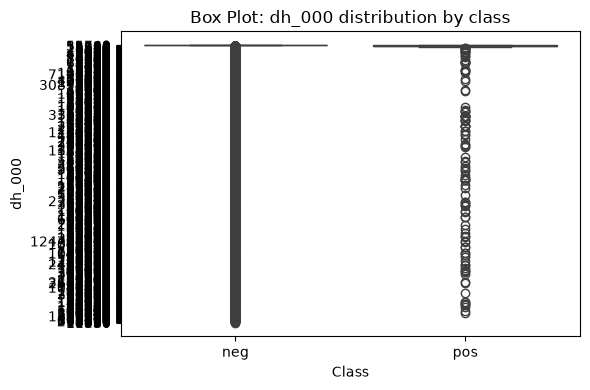

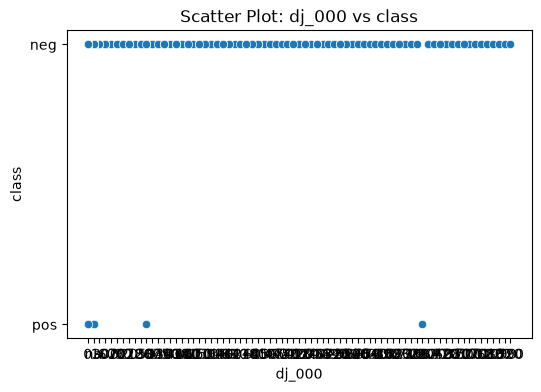

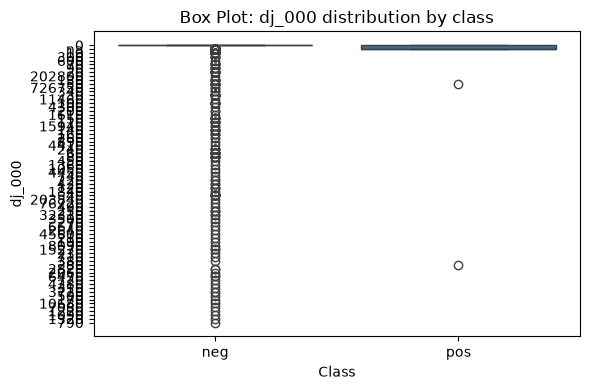

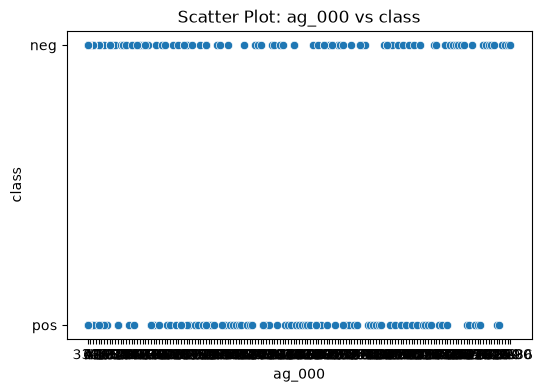

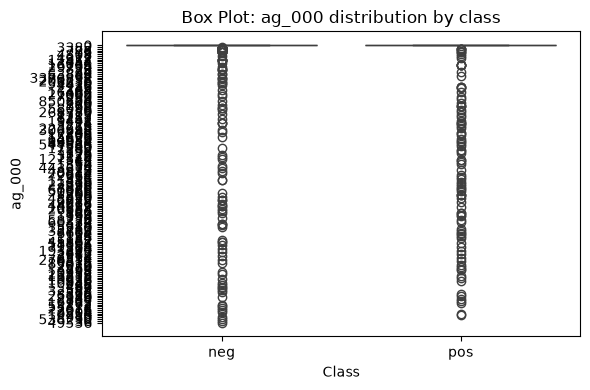

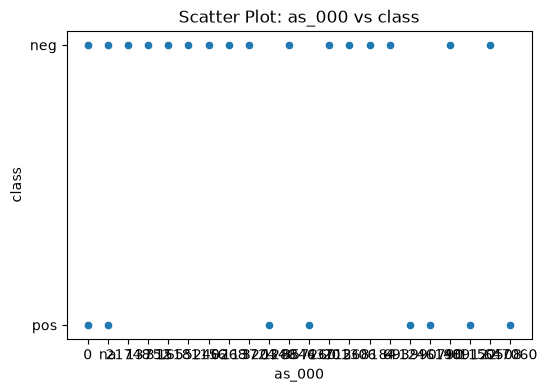

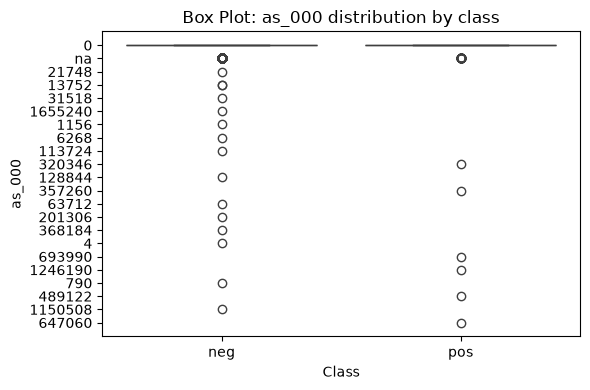

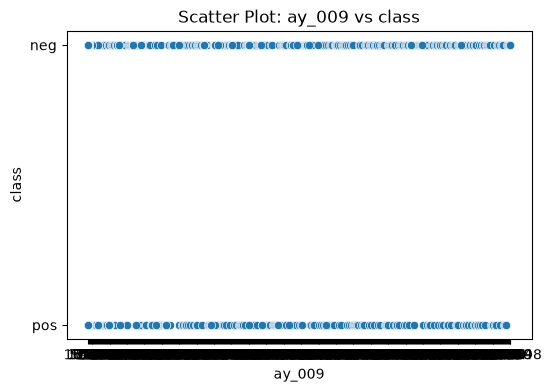

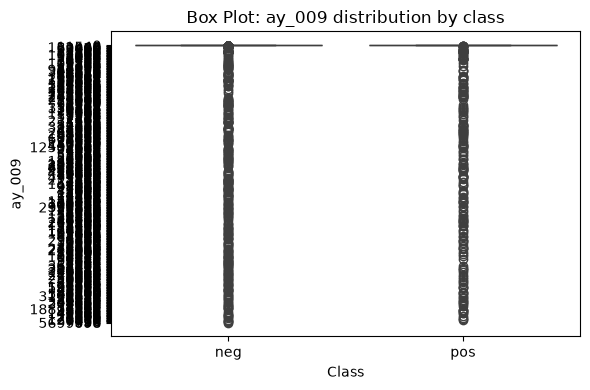

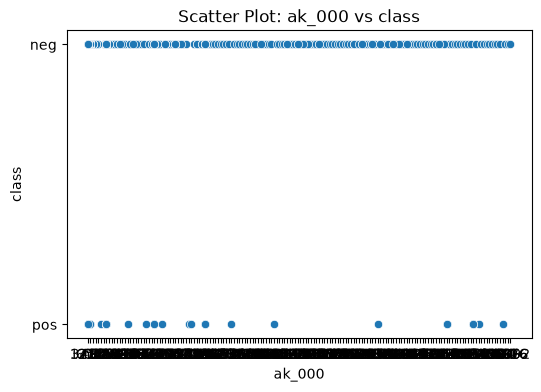

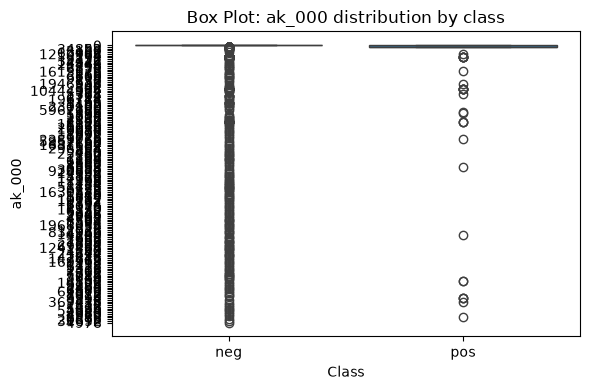

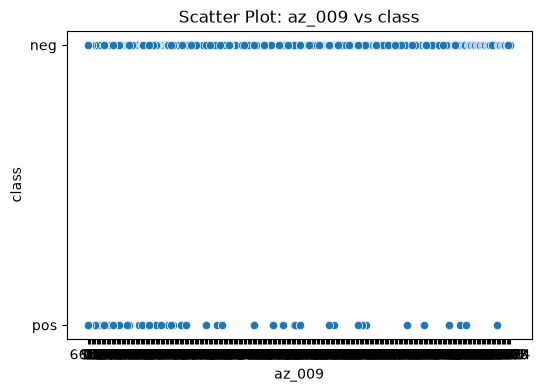

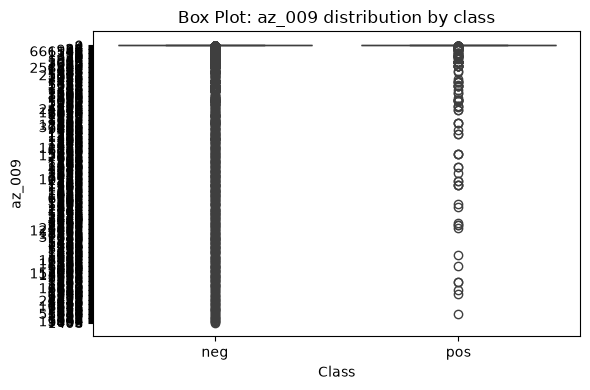

In [33]:
sorted_map = dict(sorted(res.items(), key=lambda item: float(item[1]), reverse=True))

count = 0


for feature, cv_score in sorted_map.items():
    if count >= int(128 ** 0.5):  # Stops after 11 features
        break
        
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.scatterplot(x=df[feature], y=df['class'], ax=ax)
    ax.set_title(f"Scatter Plot: {feature} vs class")
    plt.show()


    fig, ax = plt.subplots(figsize=(6, 4))
    sns.boxplot(x=df['class'], y=df[feature], ax=ax)
    ax.set_title(f"Box Plot: {feature} distribution by class")
    ax.set_xlabel("Class")
    ax.set_ylabel(feature)
    plt.tight_layout()
    plt.show()
    
    count += 1

#### (v) Is this data set imbalanced?

In [34]:
pos = 0
neg = 0
for label in labels:

    if label == 'pos':
        pos += 1
    elif label == 'neg':
        neg += 1

print(pos)
print(neg)

1000
59000


#### there are 5900 negatives and 1000 positves. The set is imbalances

### (c) Train a random forest

Confusion Matrix:
[[15613    12]
 [  113   262]]
Misclassification Error: 0.00781
AUC: 0.99380

OOB Error Estimate: 0.00607
Test Error (Misclassification): 0.00781


/var/folders/fh/bj9r3szx527_vtnjzhthgr8r0000gn/T/ipykernel_48433/777912575.py:70: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([0, 1], [0, 1], 'k--', color='gray')


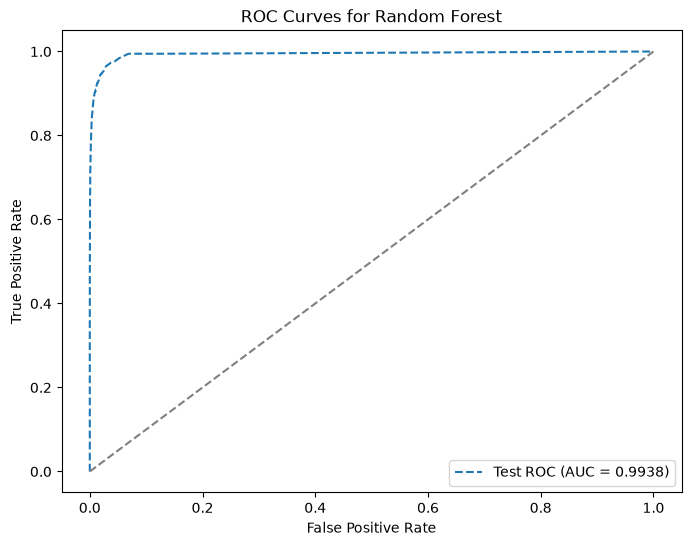

In [36]:
# how do i do this
# is this right

# rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
# rf_model.fit(features, labels)
# file_path = '/Users/bricepatchou/Documents/GitHub/DCSI552_HW6/aps_failure_test_set.csv'
# header_row = 0
# with open(file_path, 'r') as f:
#     for i, line in enumerate(f):
#         if line.startswith('class'):
#             header_row = i
#             break

# test_df = pd.read_csv(file_path, skiprows=header_row, na_values=['?'])
# test_features = test_df.drop(columns=['class']).apply(pd.to_numeric, errors='coerce')
# test_labels = test_df['class']

# y_pred = rf_model.predict(test_labels)

# 'RandomForestClassifier' object has no attribute 'oob_score_'

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, oob_score=True)
rf_model.fit(features, labels)
file_path = '/Users/bricepatchou/Documents/GitHub/DCSI552_HW6/aps_failure_test_set.csv'
header_row = 0
with open(file_path, 'r') as f:
    for i, line in enumerate(f):
        if line.startswith('class'):
            header_row = i
            break

test_df = pd.read_csv(file_path, skiprows=header_row, na_values=['?'])
test_features = test_df.drop(columns=['class']).apply(pd.to_numeric, errors='coerce')
test_labels = test_df['class']


test_features_imputed = test_features.fillna(train_medians)


y_pred = rf_model.predict(test_features_imputed)

test_preds = rf_model.predict(test_features_imputed)
test_probs = rf_model.predict_proba(test_features_imputed)[:, 1]

test_cm = confusion_matrix(test_labels, test_preds)
test_misclass = 1 - accuracy_score(test_labels, test_preds)

binary_test_labels = (test_labels == 'pos').astype(int)
test_fpr, test_tpr, _ = roc_curve(binary_test_labels, test_probs)
test_auc = auc(test_fpr, test_tpr)




oob_error = 1 - rf_model.oob_score_


print(f"Confusion Matrix:\n{test_cm}")
print(f"Misclassification Error: {test_misclass:.5f}")
print(f"AUC: {test_auc:.5f}\n")


print(f"OOB Error Estimate: {oob_error:.5f}")
print(f"Test Error (Misclassification): {test_misclass:.5f}")



plt.figure(figsize=(8, 6))
plt.plot(test_fpr, test_tpr, label=f'Test ROC (AUC = {test_auc:.4f})', linestyle='--')
plt.plot([0, 1], [0, 1], 'k--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Random Forest')
plt.legend(loc='lower right')
plt.show()

### (d) Research class imbalance in random forest

In [ ]:
rf_balanced = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    class_weight='balanced', 
    oob_score=True
)
rf_balanced.fit(features_imputed, labels)

test_preds_bal = rf_balanced.predict(test_features_imputed)
test_probs_bal = rf_balanced.predict_proba(test_features_imputed)[:, 1]

test_cm_bal = confusion_matrix(test_labels, test_preds_bal)
test_misclass_bal = 1 - accuracy_score(test_labels, test_preds_bal)

binary_test_labels = (test_labels == 'pos').astype(int)
test_fpr_bal, test_tpr_bal, _ = roc_curve(binary_test_labels, test_probs_bal)
test_auc_bal = auc(test_fpr_bal, test_tpr_bal)




oob_error_bal = 1 - rf_balanced.oob_score_




print(f"Confusion Matrix:\n{test_cm_bal}")
print(f"Misclassification Error: {test_misclass_bal:.5f}")
print(f"AUC: {test_auc_bal:.5f}\n")


print(f"OOB Error Estimate: {oob_error_bal:.5f}")
print(f"Test Error (Misclassification): {test_misclass_bal:.5f}")



#### Balancing the classes helps the model catch far more true failures, even though it causes a few more false alarms. This trade-off is crucial for safety applications like APS failure detection.

### (e) XGBoost and Model Trees

In [ ]:
# how do I do this. break it does step by step
# use the code from the last hw to help. (Pasted part j of hw 5)
y_train_bin = (labels == 'pos').astype(int)
y_test_bin = (test_labels == 'pos').astype(int)


cv_method = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {'reg_alpha': [0.01, 0.1, 1.0, 10.0],'learning_rate': [0.05, 0.1],'max_depth': [3, 5]}

xgb_base = XGBClassifier(objective='binary:logistic',eval_metric='auc',random_state=42)

grid_search = GridSearchCV(estimator=xgb_base,param_grid=param_grid,cv=cv_method,scoring='roc_auc',n_jobs=-1)


grid_search.fit(features_imputed, y_train_bin)
best_model = grid_search.best_estimator_
print(f"Best Parameters found via CV: {grid_search.best_params_}")


cv_error = 1.0 - grid_search.best_score_
print(f"Cross-Validation Error Estimate: {cv_error:.5f}")




# traning
train_preds = best_model.predict(features_imputed)
train_probs = best_model.predict_proba(features_imputed)[:, 1]

train_cm = confusion_matrix(y_train_bin, train_preds)
train_misclass = 1 - accuracy_score(y_train_bin, train_preds)
train_fpr, train_tpr, _ = roc_curve(y_train_bin, train_probs)
train_auc = auc(train_fpr, train_tpr)


# testing
test_preds = best_model.predict(test_features_imputed)
test_probs = best_model.predict_proba(test_features_imputed)[:, 1]

test_cm = confusion_matrix(y_test_bin, test_preds)
test_test_error = 1 - accuracy_score(y_test_bin, test_preds)
test_fpr, test_tpr, _ = roc_curve(y_test_bin, test_probs)
test_auc = auc(test_fpr, test_tpr)



print("training")
print(f"Confusion Matrix:\n{train_cm}")
print(f"Misclassification Error: {train_misclass:.5f}")
print(f"AUC: {train_auc:.5f}")

print("teting")
print(f"Confusion Matrix:\n{test_cm}")
print(f"Test Error: {test_test_error:.5f}")
print(f"AUC: {test_auc:.5f}")

print(f"\nComparison: CV Error ({cv_error:.5f}) vs Test Error ({test_test_error:.5f})")



plt.figure(figsize=(8, 6))
plt.plot(train_fpr, train_tpr, label=f'Train ROC (AUC = {train_auc:.4f})')
plt.plot(test_fpr, test_tpr, label=f'Test ROC (AUC = {test_auc:.4f})', linestyle='--')
plt.plot([0, 1], [0, 1], 'k--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Model Tree / XGBoost ROC Curves (No Class Imbalance Compensation)')
plt.legend(loc='lower right')
plt.show()



### (f) Use SMOTE to pre-process your data

Best Parameters with SMOTE: {'xgb__reg_alpha': 0.1}
Cross-Validation Error Estimate (with SMOTE): 0.01377
smote traing
Confusion Matrix:
[[59000     0]
 [    1   999]]
Misclassification Error: 0.00002
AUC: 0.99998
smote testing
Confusion Matrix:
[[15579    46]
 [   61   314]]
Test Error: 0.00669
AUC: 0.99356


/var/folders/fh/bj9r3szx527_vtnjzhthgr8r0000gn/T/ipykernel_48433/1856680616.py:59: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([0, 1], [0, 1], 'k--', color='gray')


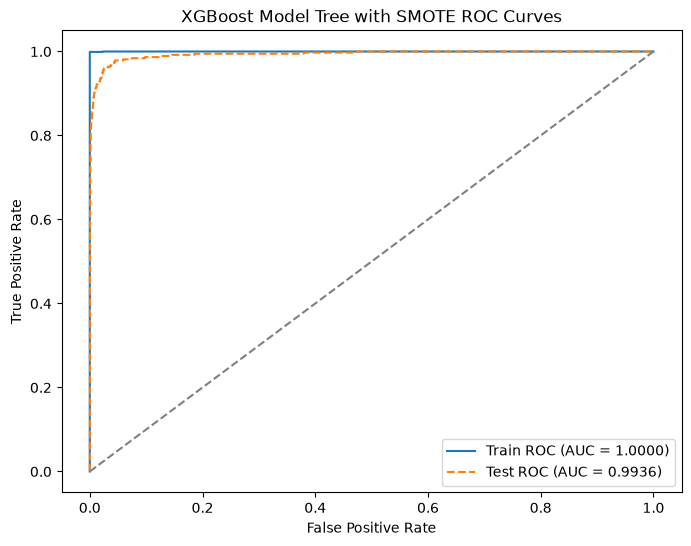

In [41]:
# help with this. how do i do this


y_train_bin = (labels == 'pos').astype(int)
y_test_bin = (test_labels == 'pos').astype(int)

pipeline = ImbPipeline([('smote', SMOTE(random_state=42)),('xgb', XGBClassifier(objective='binary:logistic',eval_metric='auc',random_state=42))])
cv_method = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_grid = {'xgb__reg_alpha': [0.01, 0.1, 1.0, 10.0],  }
grid_search = ImbPipeline([('smote', SMOTE(random_state=42)),('xgb', XGBClassifier(objective='binary:logistic', eval_metric='auc', random_state=42))])
grid_search = GridSearchCV(estimator=pipeline,param_grid=param_grid,cv=cv_method,scoring='roc_auc', n_jobs=-1)




grid_search.fit(features_imputed, y_train_bin)
best_model = grid_search.best_estimator_

print(f"Best Parameters with SMOTE: {grid_search.best_params_}")
cv_error_smote = 1.0 - grid_search.best_score_
print(f"Cross-Validation Error Estimate (with SMOTE): {cv_error_smote:.5f}")


train_preds = best_model.predict(features_imputed)
train_probs = best_model.predict_proba(features_imputed)[:, 1]

train_cm = confusion_matrix(y_train_bin, train_preds)
train_misclass = 1.0 - accuracy_score(y_train_bin, train_preds)
train_fpr, train_tpr, _ = roc_curve(y_train_bin, train_probs)
train_auc = auc(train_fpr, train_tpr)



test_preds = best_model.predict(test_features_imputed)
test_probs = best_model.predict_proba(test_features_imputed)[:, 1]

test_cm = confusion_matrix(y_test_bin, test_preds)
test_test_error = 1.0 - accuracy_score(y_test_bin, test_preds)
test_fpr, test_tpr, _ = roc_curve(y_test_bin, test_probs)
test_auc = auc(test_fpr, test_tpr)



print("smote traing")
print(f"Confusion Matrix:\n{train_cm}")
print(f"Misclassification Error: {train_misclass:.5f}")
print(f"AUC: {train_auc:.5f}")

print("smote testing")
print(f"Confusion Matrix:\n{test_cm}")
print(f"Test Error: {test_test_error:.5f}")
print(f"AUC: {test_auc:.5f}")



plt.figure(figsize=(8, 6))
plt.plot(train_fpr, train_tpr, label=f'Train ROC (AUC = {train_auc:.4f})')
plt.plot(test_fpr, test_tpr, label=f'Test ROC (AUC = {test_auc:.4f})', linestyle='--')
plt.plot([0, 1], [0, 1], 'k--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost Model Tree with SMOTE ROC Curves')
plt.legend(loc='lower right')
plt.show()

#### Without class imbalance compensation (Part e), the model exhibits poor recall and high false negatives because it predominantly predicts the majority class. Conversely, applying SMOTE (Part f) significantly improves failure detection by lowering false negatives and boosting sensitivity, though this comes at the cost of more false alarms and a slightly higher overall error rate.

## 2. ISLR 6.6.3

#### Part A: As s increases, the lasso constraint is relaxed, giving the model more flexibility to fit the training data. Consequently, the training RSS steadily decreases.
#### Part B: As s increases , flexibility grows, initially reducing test error; however, as s becomes too large, overfitting occurs and the test RSS increases.
#### Part C: As s increases, the model's flexibility and complexity grow, causing the variance of the estimates to steadily rise.
#### Part D: As s increases, the constraint is more relaxed and that allows the model to capture more complex patterns, which steadily reduces its squared bias.
#### Part E: Irreducible error is the inherint noise that cannot be reduced. It will stay constant.

## 3. ISLR 6.6.5

#### check question3.pdf

## 4. ISLR 8.4.5

#### check question4.pdf

## 5. ISLR 9.7.3

#### check question5.pdf